In [11]:
from shares.middlewares.service_options_handler import OptionHandler
from shares.middlewares.service_model_config_handler import ModelConfigHandler
from shares.modules.log import Log
from shares.modules.redis import r as redis_single
from shares.modules.minio import *
from shares.modules.tensorflow_module import TensorflowModule
from shares.modules.sklearn_module import SklearnModule
from shares.dao.runnable_services_dao import runnableServicesDao
from shares.dao.upbit_transaction_dao import UpbitTransactionDao
from shares.functions.common_function import get_years_between_str, split_date_range_by_year
from shares.functions.common_function import generate_micro_date

In [16]:

class CvAiTrainerS1Gen02(ModelConfigHandler, OptionHandler):
    slack_post_prefix = ":bee: Queen Bee."
    
    def __init__(self, seq):
        
        self.redis = redis_single
        self.tensorflow_module = TensorflowModule()
        self.sklearn_module = SklearnModule()
        self.runnable_services_dao = runnableServicesDao()
        self.upbit_transaction_dao = UpbitTransactionDao()
         
        # 옵션 오토 로드
        self.scheduler_start_day = None
        self.scheduler_start_hour = None
        self.scheduler_start_min = None
        self.auto_back_test = None
        self.auto_back_test_seq = None
        self.model_config_path = None
        self.ticker = None
        self.dataset_load_term = None
        self.dataset_table_prefix = None
        self.load_options(seq)
        
        # 모델 구성 오토 로드
        self.load_model_config(self.model_config_path)
        
        self.seq = seq
        self.model_path = ""
        
    def run(self):
        
        try:
            # 데이터 조회
            df = self.get_dataframe()
            
            # 학습 데이터 전처리
            df = self.preprocess_df_by_model_config(df)
            
            # 모델 생성
            self.redis.save_msg_on_Q(f"학습 시작, {self.minio_path}")
            model, history = self.generate_model(df)
            
            
            self.redis.save_msg_on_Q(f"학습 종료, {self.minio_path}")
            self.redis.save_msg_on_Q(f"최종 훈련 정확도 : {history.history['accuracy'][-1]}")
            self.redis.save_msg_on_Q(f"최종 검증 정확도 : {history.history['val_accuracy'][-1]}")
            
            return model, history
            
        except Exception as e:
            print(f"class : {self.__class__.__name__}, method : {inspect.currentframe().f_code.co_name}, error : {str(e)}")
    
        finally:
            if os.path.exists(local_path):
                os.remove(local_path)
        
    def get_dataframe(self):
        
        # --- 데이터 셋팅
        now_date = str(datetime.datetime.now())[0:19]
        n_days_ago = str(datetime.datetime.now() - datetime.timedelta(days=self.dataset_load_term))[0:19]   
        self.year_list = get_years_between_str(n_days_ago, now_date)  # 대상연도
        self.splited_year_dict = split_date_range_by_year(n_days_ago, now_date) 
        
        # --- 연단위 테이블 생성 (있으면 pass)
        self.upbit_transaction_dao.create_yearly_table(self.year_list)
    
        # --- 데이터 조회
        upbit_transactions_list = []
        for year in self.year_list:
            
            table_name = f"{self.dataset_table_prefix}_{year}"
            
            splited_year = self.splited_year_dict[year]
            start = splited_year[0]
            end = splited_year[1]
            
            upbit_transactions = self.upbit_transaction_dao.get_upbit_transactions_between(table_name, self.ticker, start, end)
            upbit_transactions_list += upbit_transactions
        
        if len(upbit_transactions_list) == 0:
            self.log.info(f'no dataset found')
            raise 
        
        # --- 데이터프레임으로 변환
        df = pd.DataFrame(upbit_transactions_list)
        
        return df 
    
    def generate_model(self, df):

        try:
            # 데이터 분리
            X, Y = df[self.features].values, df[self.targets[0]].values
            
            # 클래스 가중치 계산 (Y는 정수 인코딩된 라벨)
            class_weight = self.sklearn_module.calculate_class_weight(Y)
            
            # # 가중치로 인한 손실 보정 비율
            # loss_balance_ratio = 8
            # class_weight[0] = class_weight[0] - (class_weight[1] * loss_balance_ratio)/2
            # class_weight[1] = class_weight[1] * loss_balance_ratio 
            # class_weight[2] = class_weight[2] - (class_weight[1] * loss_balance_ratio)/2
                
            # # 가중치 지정 
            # class_weight = {
            #     0: 1.0,
            #     1: 2.0,
            #     2: 5.0
            # }
            # self.log.info(f'class_weight_dict : {class_weight_dict}')
            # raise
        
            # 모델 생성
            model, history = self.tensorflow_module.train_by_lstm_model(
                X, Y, 
                self.hyperparameters.get("time_steps"), 
                self.hyperparameters.get("batch_size"), 
                self.hyperparameters.get("epochs"), 
                self.hyperparameters.get("early_stop"), 
                class_weight
            )
            
            return model, history
        
        except Exception as e:
            print(f"class : {self.__class__.__name__}, method : {inspect.currentframe().f_code.co_name}, error : {str(e)}")
            self.redis.save_msg_on_Q(f"학습 중 애러: {str(datetime.datetime.now())}")
            raise

In [18]:
obj = CvAiTrainerS1Gen02(seq=11)

FileNotFoundError: [Errno 2] No such file or directory: '/apps/scheduler/model_config/cv_ai_trainer_s1_gen02_config.yaml'

In [4]:
df = get_dataframe()

In [7]:
# 중요 피쳐 확인
importances = pd.Series(model.feature_importances_, index=X.columns)
importances.nlargest(20).plot(kind='barh')

NameError: name 'model' is not defined

<Axes: >

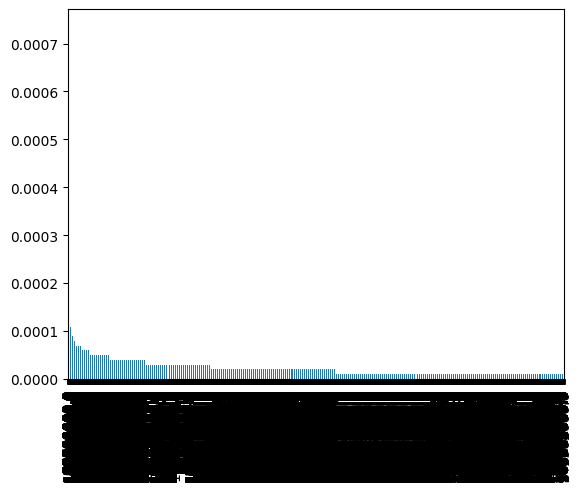

In [6]:
# 클래스 분포 확인
df['open'].value_counts(normalize=True).plot(kind='bar')